# Tugas Kelompok 2: Optimasi Model CNN (Hyperparameter Tuning)
**Mata Kuliah:** Artificial Intelligence — Kelas JWCA — Kelompok 4

**Asysyifa Isharul Jannah (2902692604)**

**Alur notebook:**
1. Load & preprocessing data CIFAR-10
2. Training model awal (baseline dari TK1)
3. Hyperparameter tuning dengan Keras Tuner (RandomSearch)
4. Training ulang model dengan hyperparameter terbaik
5. Evaluasi & perbandingan baseline vs hasil tuning
6. Simpan model terbaik sebagai `model.keras` untuk aplikasi Streamlit

> Runtime T4 GPU. Total waktu sekitar 45–60 menit.

## 1. Load & Preprocessing Data

In [1]:
!pip install -q datasets keras-tuner

import os, random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers
import keras_tuner as kt
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from sklearn.metrics import classification_report, confusion_matrix

# Seed agar hasil lebih konsisten antar-run
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

dataset = load_dataset("uoft-cs/cifar10")

x_train_all = np.array([np.array(img) for img in dataset['train']['img']])
y_train_all = np.array(dataset['train']['label']).reshape(-1, 1)
x_test_raw  = np.array([np.array(img) for img in dataset['test']['img']])
y_test_raw  = np.array(dataset['test']['label']).reshape(-1, 1)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

VAL_SIZE = 10000
x_val_raw,   y_val_raw   = x_train_all[-VAL_SIZE:], y_train_all[-VAL_SIZE:]
x_train_raw, y_train_raw = x_train_all[:-VAL_SIZE], y_train_all[:-VAL_SIZE]

# Normalisasi 0–1 (aplikasi Streamlit memakai NORMALIZATION = "rescale")
x_train = x_train_raw.astype('float32') / 255.0
x_val   = x_val_raw.astype('float32') / 255.0
x_test  = x_test_raw.astype('float32') / 255.0

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1)
], name="data_augmentation")

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train_raw))
            .shuffle(10000, seed=SEED)
            .batch(BATCH_SIZE)
            .map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE))
val_ds  = tf.data.Dataset.from_tensor_slices((x_val, y_val_raw)).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test_raw)).batch(BATCH_SIZE).prefetch(AUTOTUNE)

print(f"Data Training  : {len(x_train):,} sampel")
print(f"Data Validasi  : {len(x_val):,} sampel")
print(f"Data Testing   : {len(x_test):,} sampel")
print(f"Dimensi Input  : {x_train.shape[1:]}")
print(f"Rentang Piksel : [{x_train.min():.1f}, {x_train.max():.1f}]")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 5.9 MB/s eta 0:00:00


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Data Training  : 40,000 sampel
Data Validasi  : 10,000 sampel
Data Testing   : 10,000 sampel
Dimensi Input  : (32, 32, 3)
Rentang Piksel : [0.0, 1.0]


## 2. Model Awal (Baseline dari TK1)
Model ini menjadi pembanding. Hasil tuning dianggap berhasil jika akurasinya lebih tinggi dari baseline.

In [2]:
def build_baseline():
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(len(class_names), activation='softmax')
    ], name='cnn_baseline')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def make_callbacks(ckpt_path, patience=6):
    return [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience,
                                         restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3,
                                             min_lr=1e-6, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(ckpt_path, monitor='val_accuracy',
                                           save_best_only=True, verbose=0),
    ]

EPOCHS = 40

baseline = build_baseline()
baseline.summary()
history_base = baseline.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                            callbacks=make_callbacks('baseline.keras'), verbose=1)

base_test_loss, base_test_acc = baseline.evaluate(test_ds, verbose=0)
base_val_acc = max(history_base.history['val_accuracy'])
print(f"\nBaseline -> best val_accuracy: {base_val_acc:.4f} | test_accuracy: {base_test_acc:.4f}")

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 32s 22ms/step - accuracy: 0.3429 - loss: 1.7913 - val_accuracy: 0.4599 - val_loss: 1.5305 - learning_rate: 0.0010
Epoch 2/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.4536 - loss: 1.5185 - val_accuracy: 0.5359 - val_loss: 1.2788 - learning_rate: 0.0010
Epoch 3/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.5010 - loss: 1.3978 - val_accuracy: 0.5419 - val_loss: 1.2826 - learning_rate: 0.0010
Epoch 4/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.5302 - loss: 1.3147 - val_accuracy: 0.6037 - val_loss: 1.1182 - learning_rate: 0.0010
Epoch 5/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - accuracy: 0.5515 - loss: 1.2626 - val_accuracy: 0.6033 - val_loss: 1.1238 - learning_rate: 0.0010
Epoch 6/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.5706 - loss: 1.2076 - val_accuracy: 0.6428 - val_loss: 1.0058 - learning_rate: 0.0010
Epoch 7/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - accuracy: 0.5843 - l

## 3. Hyperparameter Tuning (Keras Tuner — RandomSearch)

**Perbaikan dibanding versi sebelumnya:**
- Model tuning kini memiliki **3 blok konvolusi** (sebelumnya hanya 2, sehingga lebih sederhana dari baseline).
- **Batch Normalization** ikut diuji (dipakai / tidak).
- Jumlah kombinasi dinaikkan dari 3 menjadi **10 trial**.
- `overwrite=True` agar tuning benar-benar dijalankan ulang, bukan memuat hasil lama.

| Hyperparameter | Nilai yang diuji |
|---|---|
| Filter blok 1 | 32, 64 |
| Filter blok 2 | 64, 128 |
| Filter blok 3 | 128, 256 |
| Batch Normalization | Ya / Tidak |
| Dense units | 128, 256 |
| Dropout | 0.2 – 0.5 |
| Learning rate | 0.001, 0.0005, 0.0001 |

In [3]:
def build_model(hp):
    use_bn = hp.Boolean('batch_norm')
    model = tf.keras.Sequential(name='cnn_tuned')
    model.add(tf.keras.Input(shape=(32, 32, 3)))

    for i, choices in enumerate([[32, 64], [64, 128], [128, 256]], start=1):
        model.add(layers.Conv2D(hp.Choice(f'filters_{i}', choices), (3, 3), padding='same'))
        if use_bn:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation('relu'))
        model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(hp.Choice('units', [128, 256]), activation='relu'))
    model.add(layers.Dropout(hp.Float('dropout', 0.2, 0.5, step=0.1)))
    model.add(layers.Dense(len(class_names), activation='softmax'))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=hp.Choice('learning_rate', [1e-3, 5e-4, 1e-4])),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])
    return model

MAX_TRIALS = 10        # kurangi ke 6 jika waktu Colab terbatas
SEARCH_EPOCHS = 12     # epoch per trial saat pencarian

tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=MAX_TRIALS,
    executions_per_trial=1,
    directory='cifar10_tuning',
    project_name='cnn_cifar10_tk2',
    overwrite=True,
    seed=SEED,
)
tuner.search_space_summary()

tuner.search(train_ds, validation_data=val_ds, epochs=SEARCH_EPOCHS,
             callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3,
                                                         restore_best_weights=True)],
             verbose=1)

Trial 10 Complete [00h 03m 00s]
val_accuracy: 0.5428000092506409

Best val_accuracy So Far: 0.7239000201225281
Total elapsed time: 00h 27m 58s


### 3.1 Tabel Hasil Semua Trial (untuk Bab II laporan)

In [4]:
rows = []
for t in tuner.oracle.get_best_trials(num_trials=MAX_TRIALS):
    hp = t.hyperparameters.values
    rows.append({
        'Trial': t.trial_id,
        'Filter 1': hp['filters_1'], 'Filter 2': hp['filters_2'], 'Filter 3': hp['filters_3'],
        'BatchNorm': 'Ya' if hp['batch_norm'] else 'Tidak',
        'Dense': hp['units'], 'Dropout': round(hp['dropout'], 1),
        'Learning rate': hp['learning_rate'],
        'Val accuracy': round(t.score, 4) if t.score is not None else None,
    })
trials_df = pd.DataFrame(rows).sort_values('Val accuracy', ascending=False).reset_index(drop=True)
trials_df.index = trials_df.index + 1
trials_df.to_csv('hasil_tuning.csv', index_label='Peringkat')
display(trials_df)

best_hps = tuner.get_best_hyperparameters(1)[0]
print("\nHYPERPARAMETER TERBAIK:")
for k, v in best_hps.values.items():
    print(f"  - {k:<14}: {v}")

,Trial,Filter 1,Filter 2,Filter 3,BatchNorm,Dense,Dropout,Learning rate,Val accuracy
1,06,32,128,256,Tidak,256,0.3,0.0010,0.7239
2,01,32,64,256,Tidak,256,0.4,0.0010,0.7100
3,00,32,64,128,Ya,256,0.3,0.0005,0.6529
4,04,64,64,128,Ya,256,0.2,0.0005,0.6187
5,05,32,128,128,Ya,128,0.2,0.0010,0.6123
6,02,32,128,128,Ya,128,0.3,0.0001,0.5453
7,08,64,64,128,Ya,128,0.4,0.0001,0.5449
8,09,32,64,256,Tidak,256,0.2,0.0001,0.5428
9,03,32,64,128,Tidak,128,0.4,0.0001,0.5002
10,07,32,64,256,Tidak,128,0.4,0.0001,0.4991



HYPERPARAMETER TERBAIK:
  - batch_norm    : False
  - filters_1     : 32
  - filters_2     : 128
  - filters_3     : 256
  - units         : 256
  - dropout       : 0.30000000000000004
  - learning_rate : 0.001


## 4. Training Ulang Model dengan Hyperparameter Terbaik

Model: "cnn_tuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,384,458 (5.28 MB)

 Trainable params: 1,384,458 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.3591 - loss: 1.7481 - val_accuracy: 0.4803 - val_loss: 1.4432 - learning_rate: 0.0010
Epoch 2/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.4804 - loss: 1.4402 - val_accuracy: 0.5699 - val_loss: 1.1831 - learning_rate: 0.0010
Epoch 3/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.5245 - loss: 1.3229 - val_accuracy: 0.5830 - val_loss: 1.1675 - learning_rate: 0.0010
Epoch 4/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.5611 - loss: 1.2318 - val_accuracy: 0.5842 - val_loss: 1.2076 - learning_rate: 0.0010
Epoch 5/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.5841 - loss: 1.1722 - val_accuracy: 0.6041 - val_loss: 1.1174 - learning_rate: 0.0010
Epoch 6/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.6050 - loss: 1.1246 - val_accuracy: 0.6484 - val_loss: 1.0247 - learning_rate: 0.0010
Epoch 7/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.6196 - l

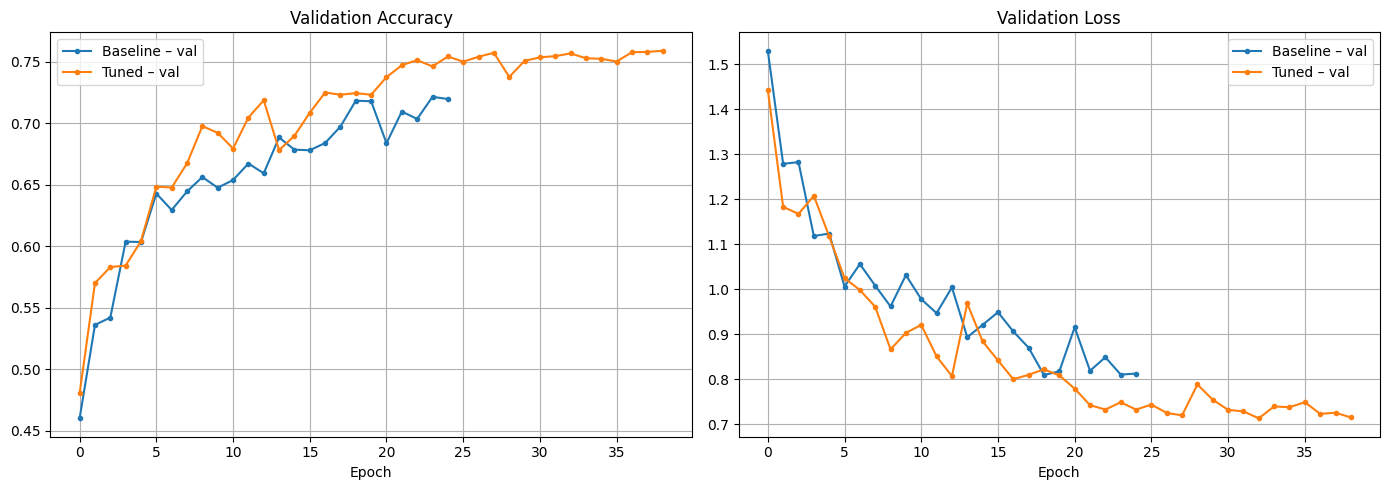

In [5]:
tuned = tuner.hypermodel.build(best_hps)
tuned.summary()
history_tuned = tuned.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                          callbacks=make_callbacks('tuned.keras'), verbose=1)

tuned_test_loss, tuned_test_acc = tuned.evaluate(test_ds, verbose=0)
tuned_val_acc = max(history_tuned.history['val_accuracy'])
print(f"\nTuned -> best val_accuracy: {tuned_val_acc:.4f} | test_accuracy: {tuned_test_acc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for h, name in [(history_base, 'Baseline'), (history_tuned, 'Tuned')]:
    axes[0].plot(h.history['val_accuracy'], marker='o', markersize=3, label=f'{name} – val')
    axes[1].plot(h.history['val_loss'], marker='o', markersize=3, label=f'{name} – val')
axes[0].set_title('Validation Accuracy'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True)
axes[1].set_title('Validation Loss');     axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.savefig('perbandingan_training.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. Evaluasi & Perbandingan Baseline vs Tuned

,Model,Best val accuracy,Test accuracy,Test loss,Jumlah parameter
0,Baseline (TK1),0.7215,0.7105,0.8247,356810
1,Hasil tuning,0.7590,0.7531,0.7325,1384458


Selisih test accuracy (tuned - baseline): +4.26 poin persen
Model final yang dipakai di aplikasi: Hasil tuning

Classification report model final:
              precision    recall  f1-score   support

    airplane     0.7711    0.8420    0.8050      1000
  automobile     0.8286    0.8990    0.8624      1000
        bird     0.8186    0.5910    0.6864      1000
         cat     0.6603    0.5210    0.5824      1000
        deer     0.7883    0.5770    0.6663      1000
         dog     0.6985    0.6720    0.6850      1000
        frog     0.6617    0.8800    0.7554      1000
       horse     0.7383    0.8550    0.7924      1000
        ship     0.8874    0.8350    0.8604      1000
       truck     0.7225    0.8590    0.7848      1000

    accuracy                         0.7531     10000
   macro avg     0.7575    0.7531    0.7480     10000
weighted avg     0.7575    0.7531    0.7480     10000



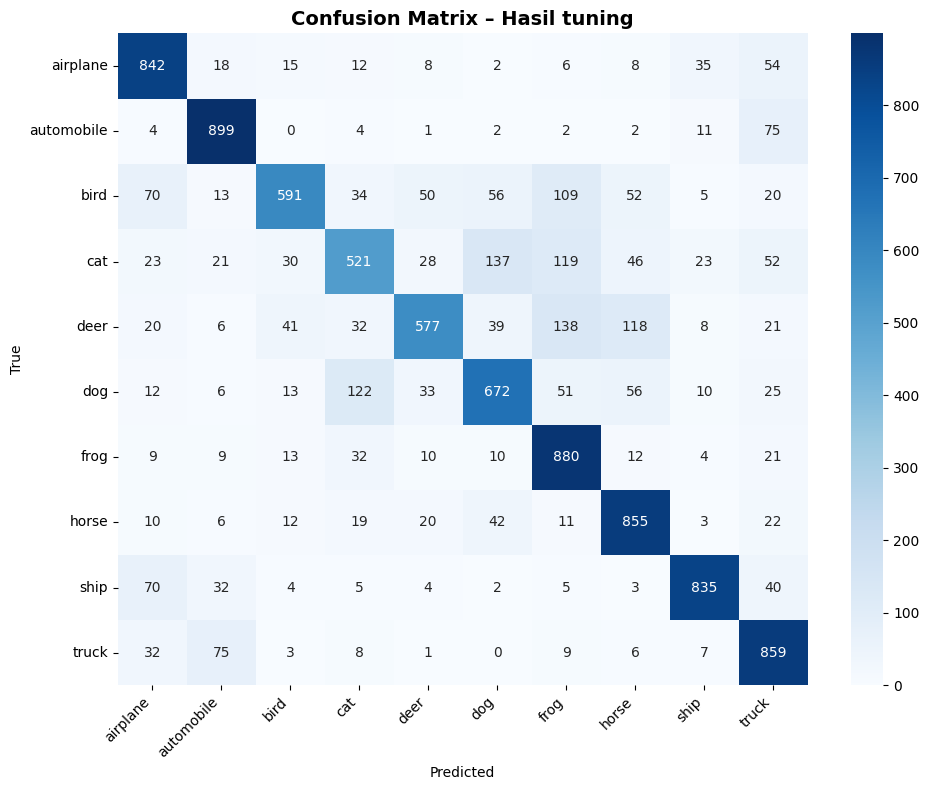

In [6]:
compare_df = pd.DataFrame({
    'Model': ['Baseline (TK1)', 'Hasil tuning'],
    'Best val accuracy': [round(base_val_acc, 4), round(tuned_val_acc, 4)],
    'Test accuracy': [round(base_test_acc, 4), round(tuned_test_acc, 4)],
    'Test loss': [round(base_test_loss, 4), round(tuned_test_loss, 4)],
    'Jumlah parameter': [baseline.count_params(), tuned.count_params()],
})
display(compare_df)
compare_df.to_csv('perbandingan_model.csv', index=False)

diff = (tuned_test_acc - base_test_acc) * 100
print(f"Selisih test accuracy (tuned - baseline): {diff:+.2f} poin persen")

# Pilih model final berdasarkan validation accuracy (test set hanya untuk pelaporan)
final_model, final_name = (tuned, 'Hasil tuning') if tuned_val_acc >= base_val_acc else (baseline, 'Baseline (TK1)')
print(f"Model final yang dipakai di aplikasi: {final_name}")

y_true = y_test_raw.flatten()
y_pred = np.argmax(final_model.predict(test_ds, verbose=0), axis=1)
print("\nClassification report model final:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix – {final_name}', fontsize=14, fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight'); plt.show()

## 6. Simpan Model untuk Aplikasi Streamlit
File `model.keras` di-upload ke folder `model/` di GitHub (menimpa model dummy).

In [7]:
final_model.save('model.keras')
size_mb = os.path.getsize('model.keras') / 1e6
print(f"Tersimpan: model.keras ({size_mb:.1f} MB)")
print("Upload via browser GitHub OK" if size_mb < 25 else "Lebih dari 25 MB: upload lewat GitHub Desktop")

print("\nKonfigurasi untuk app.py:")
print(f"IMG_SIZE = {tuple(final_model.input_shape[1:3])}")
print(f"CLASS_NAMES = {class_names}")
print('NORMALIZATION = "rescale"')

# Download file penting (khusus Google Colab)
try:
    from google.colab import files
    for f in ['model.keras', 'hasil_tuning.csv', 'perbandingan_model.csv',
              'perbandingan_training.png', 'confusion_matrix.png']:
        files.download(f)
except ImportError:
    print("Bukan di Colab: ambil file dari folder kerja secara manual.")

Tersimpan: model.keras (16.7 MB)
Upload via browser GitHub OK

Konfigurasi untuk app.py:
IMG_SIZE = (32, 32)
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
NORMALIZATION = "rescale"


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>